<a href="https://colab.research.google.com/github/castr1x/ML_an.nykoliuk_3-12/blob/main/%D0%9B%D0%A03_%D0%9D%D0%B8%D0%BA%D0%BE%D0%BB%D1%8E%D0%BA_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [55]:
# Ваш код:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.





## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [56]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "house_price_regression_dataset.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "prokshitha/home-value-insights",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

df.head()



/tmp/ipykernel_873/3353369978.py:12: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'home-value-insights' dataset.


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [57]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

df.head()



,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [58]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.
df.head()




,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [60]:
# Ваш код:
# Порахуйте кількість дублікатів.
df.duplicated().sum()




np.int64(0)

### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [61]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.
for i in df.columns:
  print(i, df[i].isna().sum(), sep = ': ')




Square_Footage: 0
Num_Bedrooms: 0
Num_Bathrooms: 0
Year_Built: 0
Lot_Size: 0
Garage_Size: 0
Neighborhood_Quality: 0
House_Price: 0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [62]:
# Ваш код:
# Отримайте описову статистику датасету.

df.describe()



,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [63]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.

df.Neighborhood_Quality.value_counts()


,count
Neighborhood_Quality,
10,123
5,109
2,105
7,102
6,101
4,99
8,97
1,91
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

<Axes: xlabel='Neighborhood_Quality'>

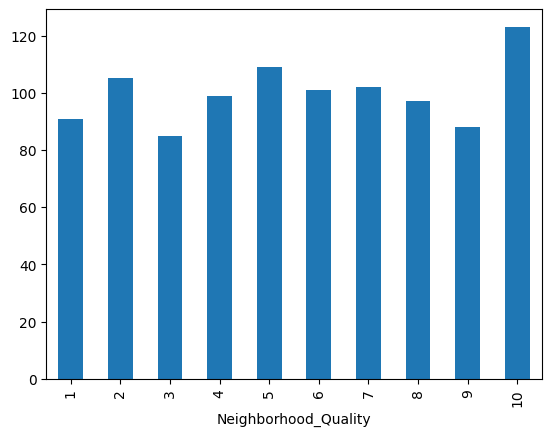

In [64]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
df.Neighborhood_Quality.value_counts().sort_index().plot(kind = 'bar')





### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [65]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.

df.Num_Bathrooms.value_counts().sort_index()




,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

<Axes: xlabel='Num_Bathrooms'>

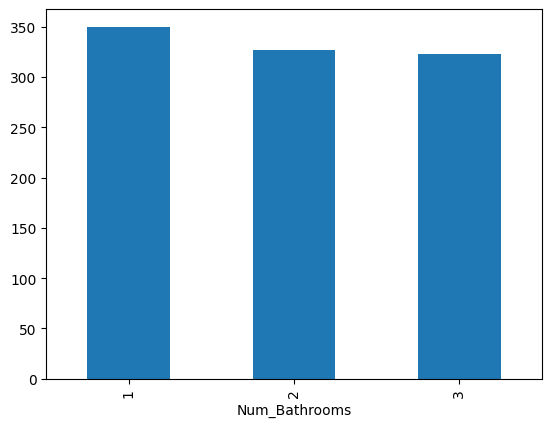

In [66]:
# Ваш код:
# Побудуйте відповідну діаграму.

df.Num_Bathrooms.value_counts().sort_index().plot(kind = 'bar')



### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

In [67]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

<Axes: >

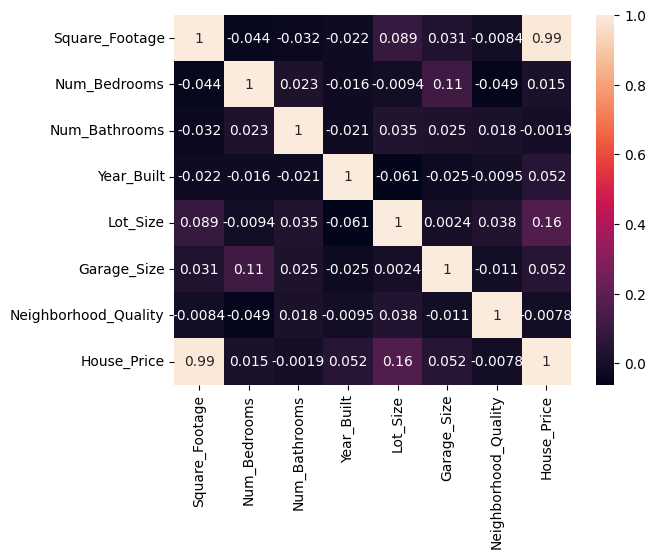

In [68]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
sns.heatmap(df.corr(numeric_only = True), annot = True)




### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [69]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.
df.corr()['House_Price'].sort_values(ascending = False)




,House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [70]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline



### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [71]:
# Ваш код:
# Створіть `X` та `y`.


y = df['House_Price']

x = df.copy().drop('House_Price', axis = 1)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [72]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.


X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    train_size=0.8,
    random_state = 42
    )

### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [73]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.

models = {
    'Linear' : make_pipeline(StandardScaler(),LinearRegression()),
    'Ridge' : make_pipeline(StandardScaler(),Ridge()),
    'Lasso' : make_pipeline(StandardScaler(),Lasso()),
    'Forest' : RandomForestRegressor(),
    'Gradient' : GradientBoostingRegressor()
}






### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [74]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
result = []

for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  r_2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)

  result.append(
      {
          'Model' : name,
          "R2" : r_2,
          'MAE' : mae,
          'MSE' : mse
      }
  )

result_df = pd.DataFrame(result)

result_df

,Model,R2,MAE,MSE
0,Linear,0.998426,8174.583600,1.014348e+08
1,Ridge,0.998410,8241.586911,1.024810e+08
2,Lasso,0.998426,8174.748374,1.014366e+08
3,Forest,0.994038,15866.203098,3.843032e+08
4,Gradient,0.996510,12304.613917,2.249538e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

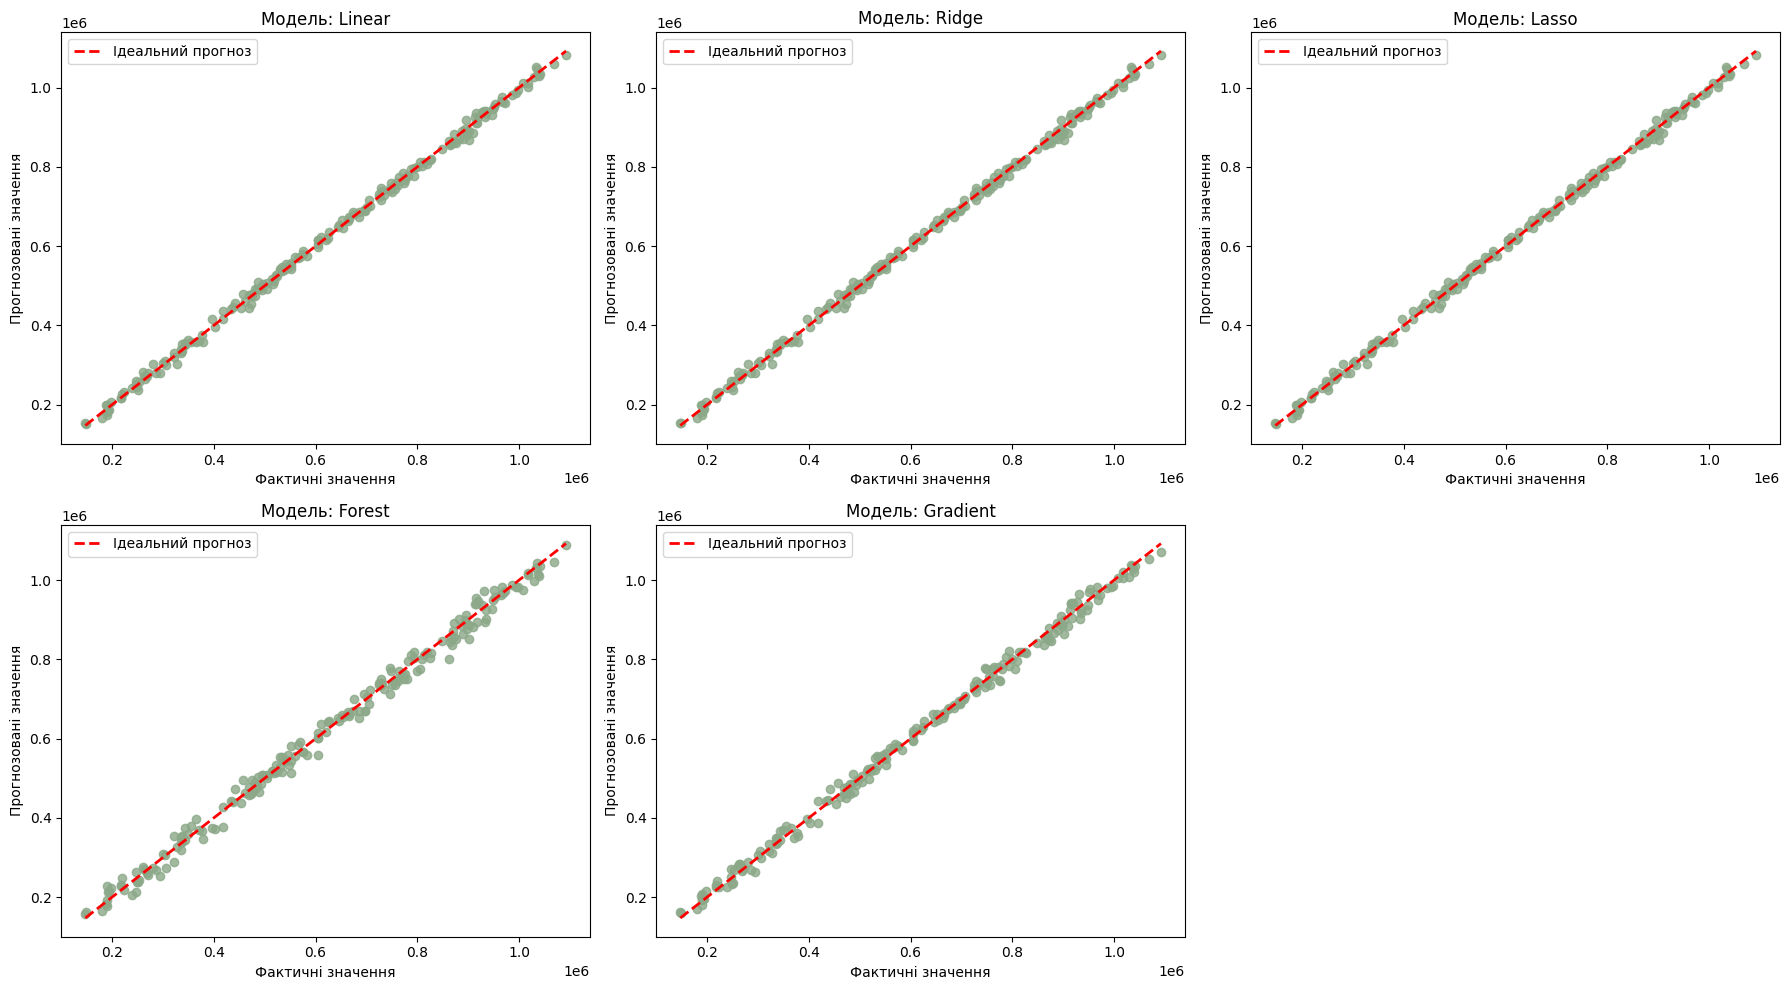

In [75]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)

    axes[i].scatter(y_test, y_pred, alpha=0.8, color='#8ba888')

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    axes[i].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз')

    axes[i].set_title(f'Модель: {name}')
    axes[i].set_xlabel('Фактичні значення')
    axes[i].set_ylabel('Прогнозовані значення')
    axes[i].legend()

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [77]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators' : np.array([50,100,150,200]),
    'max_features' : [None, 'sqrt', 'log2'],
    'max_depth' : [None, 5,10,20],
    'min_samples_split' : [2,5,10]
 }
base_model = RandomForestRegressor(random_state=67)

search = GridSearchCV(
    estimator = base_model,
    param_grid=param_grid,
    scoring='r2',
    n_jobs = -1
)

search.fit(X_train,y_train)

GridSearchCV(estimator=RandomForestRegressor(random_state=67), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 20],
                         'max_features': [None, 'sqrt', 'log2'],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': array([ 50, 100, 150, 200])},
             scoring='r2')

In [83]:
print('найкращий набір параметрів','\n')
for par, val in search.best_params_.items():
  print(par, val, sep = ' : ')

print(f'\nНайкращий результат R^2 : {search.best_score_}')

найкращий набір параметрів 

max_depth : None
max_features : None
min_samples_split : 2
n_estimators : 200

Найкращий результат R^2 : 0.9920078642413553


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [92]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.
optimized_forest = search.best_estimator_
optimized_forest.fit(X_train, y_train)

y_pred_optimized = optimized_forest.predict(X_test)

r2_optimized = r2_score(y_pred = y_pred_optimized, y_true = y_test)
mae_optimized = mean_absolute_error(y_pred = y_pred_optimized, y_true = y_test)
mse_optimized = mean_squared_error(y_pred = y_pred_optimized, y_true = y_test)



print('Оптимізована Random Forest')
print(f"R^2 - {r2_optimized:.4f}")
print(f"MSE - {mse_optimized:.2f}")
print(f"MAE - {mae_optimized:.2f}")




Оптимізована Random Forest
R^2 - 0.9942
MSE - 376947504.09
MAE - 15815.86


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [98]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.

forest_result_df = result_df[result_df['Model']=='Forest']

optimized_result = pd.DataFrame([{
    'Model': 'Optimized Forest',
    'R2' : r2_optimized,
    'MAE' : mae_optimized,
    'MSE' : mse_optimized
}])

In [121]:
df_comp = pd.concat([forest_result_df, optimized_result], ignore_index=True)
df_comp

,Model,R2,MAE,MSE
0,Forest,0.994038,15866.203098,3.843032e+08
1,Optimized Forest,0.994152,15815.861560,3.769475e+08


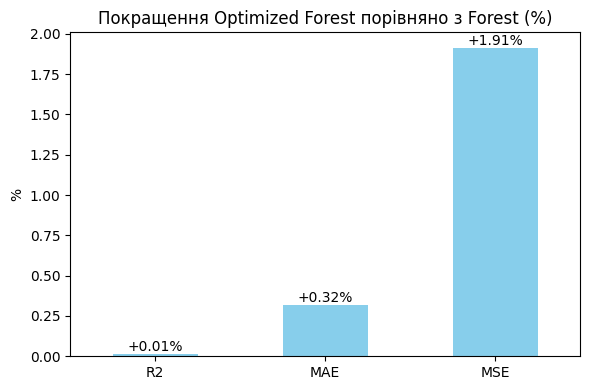

In [126]:
delta = (df_comp.iloc[1, 1:] - df_comp.iloc[0, 1:]) / df_comp.iloc[0, 1:] * 100
delta['MAE'] *= -1
delta['MSE'] *= -1

ax = delta.plot(kind='bar', color='skyblue', figsize=(6, 4))
plt.title("Покращення Optimized Forest порівняно з Forest (%)")
plt.ylabel("%")
plt.xticks(rotation=0)

for p in ax.patches:
    ax.annotate(f"{p.get_height():+.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Якість моделі після підбору параметрів трохи покращилася. Метрика R2 зросла на 0.01%, а помилки MAE та MSE зменшилися на 0.32% і 1.91% відповідно. Оптимізовану модель варто використовувати, бо вона робить менше великих помилок.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
'Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [127]:
lr_model = models['Linear']
y_pred_lr = lr_model.predict(X_test)

lr_analysis = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_lr,
})

lr_analysis['Percentage Error (%)'] = (
    np.abs(lr_analysis['Actual Price'] - lr_analysis['Predicted Price'])
    / lr_analysis['Actual Price'] * 100
)

lr_analysis.sample(10, random_state=67)




,Actual Price,Predicted Price,Percentage Error (%)
32,771922.849821,783583.197788,1.510559
77,188531.423457,198305.115228,5.184118
71,875981.026895,860886.663126,1.723138
166,895675.554821,917379.804209,2.423227
187,605600.950741,606021.461112,0.069437
25,402213.421893,396997.786413,1.296733
172,515813.757835,504865.248960,2.122570
62,322312.862508,321235.452782,0.334275
117,882532.548933,870859.130148,1.322718
123,219426.924488,228202.865019,3.999482


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

У ході лабораторної роботи було побудовано та порівняно п'ять моделей регресії, серед яких лінійні моделі та Gradient Boosting показали найвищу точність із R^2 близько 0.999. Оптимізація гіперпараметрів Random Forest через GridSearchCV дозволила додатково зменшити помилки MSE та MAE, що підтвердило доцільність налаштування параметрів для деревоподібних алгоритмів. Прогнози моделей виявилися високоточними з похибкою менше ніж 1%, а основними факторами впливу на вартість нерухомості стали житлова площа, розмір ділянки та якість району.